In [7]:
import pandas as pd 
import numpy as np
import matplotlib  as plt
import seaborn as sns

In [8]:
titanic = pd.read_csv("train.csv")

In [9]:
titanic['Survived'].value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

<Axes: ylabel='count'>

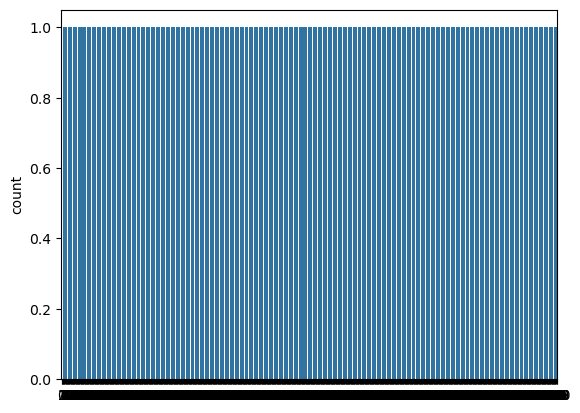

In [10]:
sns.countplot(titanic['Survived'])

In [11]:
 for val in titanic:
     print(titanic[val].value_counts())
     print()

PassengerId
1      1
599    1
588    1
589    1
590    1
      ..
301    1
302    1
303    1
304    1
891    1
Name: count, Length: 891, dtype: int64

Survived
0    549
1    342
Name: count, dtype: int64

Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Name
Braund, Mr. Owen Harris                     1
Boulos, Mr. Hanna                           1
Frolicher-Stehli, Mr. Maxmillian            1
Gilinski, Mr. Eliezer                       1
Murdlin, Mr. Joseph                         1
                                           ..
Kelly, Miss. Anna Katherine "Annie Kate"    1
McCoy, Mr. Bernard                          1
Johnson, Mr. William Cahoone Jr             1
Keane, Miss. Nora A                         1
Dooley, Mr. Patrick                         1
Name: count, Length: 891, dtype: int64

Sex
male      577
female    314
Name: count, dtype: int64

Age
24.00    30
22.00    27
18.00    26
19.00    25
28.00    25
         ..
36.50     1
55.50     1
0.92      1
23.50     1


In [12]:
titanic.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [13]:
titanic = titanic.drop(['PassengerId','Name','Ticket','Cabin'] , axis = 1)

In [14]:
titanic = titanic.dropna( subset = ['Embarked', 'Age'])

In [15]:
titanic.shape

(712, 8)

In [27]:
titanic = titanic.join(pd.get_dummies(titanic.Sex)).drop(['Sex'],axis = 1)

AttributeError: 'DataFrame' object has no attribute 'Sex'

In [28]:
titanic

,Survived,Pclass,Age,SibSp,Parch,Fare,C,Q,S,female,male
0,0,3,22.0,1,0,7.2500,0,0,1,0,1
1,1,1,38.0,1,0,71.2833,1,0,0,1,0
2,1,3,26.0,0,0,7.9250,0,0,1,1,0
3,1,1,35.0,1,0,53.1000,0,0,1,1,0
4,0,3,35.0,0,0,8.0500,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
885,0,3,39.0,0,5,29.1250,0,1,0,1,0
886,0,2,27.0,0,0,13.0000,0,0,1,0,1
887,1,1,19.0,0,0,30.0000,0,0,1,1,0
889,1,1,26.0,0,0,30.0000,1,0,0,0,1


In [29]:
change = ['female', 'male', 'C', 'Q', 'S']
titanic[change] = titanic[change].astype(int)



In [30]:
titanic

,Survived,Pclass,Age,SibSp,Parch,Fare,C,Q,S,female,male
0,0,3,22.0,1,0,7.2500,0,0,1,0,1
1,1,1,38.0,1,0,71.2833,1,0,0,1,0
2,1,3,26.0,0,0,7.9250,0,0,1,1,0
3,1,1,35.0,1,0,53.1000,0,0,1,1,0
4,0,3,35.0,0,0,8.0500,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...
885,0,3,39.0,0,5,29.1250,0,1,0,1,0
886,0,2,27.0,0,0,13.0000,0,0,1,0,1
887,1,1,19.0,0,0,30.0000,0,0,1,1,0
889,1,1,26.0,0,0,30.0000,1,0,0,0,1


In [31]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()


In [32]:
from sklearn.model_selection import train_test_split


In [33]:
X = titanic.drop(['Survived'],axis = 1)
y = titanic['Survived']

In [34]:
X_train , X_test, y_train , y_test = train_test_split(X,y, test_size = 0.2, random_state = 42)

In [35]:
lr.fit(X_train , y_train)


LinearRegression()

In [40]:
Score =print(lr.score(X_train, y_train))
Trainii = print(lr.score(X_test, y_test))    
print("Test accuracy:", Score)
print("Test accuracy taining :", Trainii)


0.8066783831282952
0.7972027972027972
Test accuracy: None
Test accuracy taining : None


In [37]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(X_train, y_train)

score = lr.score(X_test, y_test)
print("Test accuracy:", score)


Test accuracy: 0.8041958041958042


C:\Users\Kunch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [38]:
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)
score = lr.score(X_test, y_test)
print("Test accuracy:", score)


Test accuracy: 0.7972027972027972
